# 1. The Business Problem and Data

## The Business Problem
The telecommunications company is experiencing customer churn and wants to identify customers who are at risk of leaving. Because its retention budget is limited, the company needs a predictive model that can help it prioritise customers for retention activities. By analysing customer characteristics and service information, the company hopes to identify churn patterns and make better decisions about where to direct its resources.

What question are we trying to answer?

Can we predict whether a customer will churn using their available customer and service information?

There are two possible outcomes:

0 — the customer does not churn.
1 — the customer churns.

Your target variable is Churn.


In [1]:
# Importing Libraries before work


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.precision", 3)
plt.rcParams["figure.figsize"] = (7, 4)

def check(label, test, hint=""):
    """Self-check helper: prints ✅ or ❌ (with a hint)."""
    try:
        ok = bool(test())
    except Exception as e:
        ok, hint = False, f"{hint}  (error: {type(e).__name__}: {e})"
    print(("✅ " if ok else "❌ ") + label + ("" if ok else f"\n   hint: {hint}"))

print("Ready!")

Ready!


In [2]:
# 1.2 Load the data

df = pd.read_csv(r"C:\DATA SCIENCE\WA_Fn-UseC_-Telco-Customer-Churn.csv")
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


In [3]:
# 1.3 Inspect the dataset
df.shape

(7043, 21)

In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [6]:
# Inspect the column names
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [7]:
# Examine numerical summary statistics
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000,7043.000,7043.000
mean,0.162,32.371,64.762
std,0.369,24.559,30.090
min,0.000,0.000,18.250
25%,0.000,9.000,35.500
50%,0.000,29.000,70.350
75%,0.000,55.000,89.850
max,1.000,72.000,118.750


In [8]:
# For a summary that also includes categorical columns
df.describe(include="all")

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000,7043,7043,7043.000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,20.2,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162,NaN,NaN,32.371,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.762,NaN,NaN
std,NaN,NaN,0.369,NaN,NaN,24.559,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090,NaN,NaN
min,NaN,NaN,0.000,NaN,NaN,0.000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250,NaN,NaN
25%,NaN,NaN,0.000,NaN,NaN,9.000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500,NaN,NaN
50%,NaN,NaN,0.000,NaN,NaN,29.000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350,NaN,NaN
75%,NaN,NaN,0.000,NaN,NaN,55.000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850,NaN,NaN


The dataset has 7,043 rows and 21 columns.
The target variable is Churn.
The dataset includes categorical and numerical variables.
The target represents a binary classification outcome.

# 2 Data Cleaning

In [9]:
# 2.1 Check for missing values
# Count missing values in each column
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [12]:
# Checking for blank strings
df.select_dtypes(include="object").apply(
    lambda column: column.str.strip().eq("").sum()
)

C:\Users\akinl\AppData\Local\Temp\ipykernel_37160\709586457.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(include="object").apply(


customerID           0
gender               0
Partner              0
Dependents           0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
TotalCharges        11
Churn                0
dtype: int64

In [ ]:
# The main issue: TotalCharges is a string (str), not a number. I am converting it to a float
df["TotalCharges"].dtype

dtype('float64')

In [16]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].astype("string").str.strip().replace("", pd.NA),
    errors="coerce"
)

In [23]:
df["TotalCharges"].dtype


Float64Dtype()

In [24]:
df["TotalCharges"].isnull().sum()

np.int64(0)

In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [21]:
# 2.2 Check for duplicate records
# Count fully duplicated rows
df.duplicated().sum()

np.int64(0)

In [22]:
# 2.3 Check data types
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        Float64
Churn                   str
dtype: object

In [ ]:
# There are no duplicate values in the data set and now i will check for the unique values in the data set
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000,7043.000,7043.000,7043.0
mean,0.162,32.371,64.762,2279.734
std,0.369,24.559,30.090,2266.794
min,0.000,0.000,18.250,0.0
25%,0.000,9.000,35.500,398.55
50%,0.000,29.000,70.350,1394.55
75%,0.000,55.000,89.850,3786.6
max,1.000,72.000,118.750,8684.8


In [ ]:
# There are no outliers in the data set


In [26]:
print(df[["tenure", "MonthlyCharges", "TotalCharges"]].corr())

                tenure  MonthlyCharges  TotalCharges
tenure           1.000           0.248         0.826
MonthlyCharges   0.248           1.000         0.651
TotalCharges     0.826           0.651         1.000


In [ ]:
# Selecting the Key features and cleaning the target variable


In [31]:
# Checking the values in the target
df["Churn"].value_counts(dropna=False)

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [32]:
# Converting into binary variables
df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

In [33]:
df["Churn"].value_counts(dropna=False)

Churn
0    5174
1    1869
Name: count, dtype: int64

In [38]:
# Calculate the highest and lowest churn rates for each feature
feature_ranking = (
    churn_analysis
    .groupby("Feature")
    .agg(
        Highest_Churn_Rate=("Churn_Rate_%", "max"),
        Lowest_Churn_Rate=("Churn_Rate_%", "min"),
        Total_Customers=("Customers", "sum"),
        Number_of_Categories=("Category", "nunique")
    )
)

# Calculate the difference between the highest and lowest rates
feature_ranking["Churn_Rate_Range"] = (
    feature_ranking["Highest_Churn_Rate"]
    - feature_ranking["Lowest_Churn_Rate"]
)

# Rank the features by churn-rate range
feature_ranking = feature_ranking.sort_values(
    by="Churn_Rate_Range",
    ascending=False
)

feature_ranking

,Highest_Churn_Rate,Lowest_Churn_Rate,Total_Customers,Number_of_Categories,Churn_Rate_Range
Feature,,,,,
customerID,100.000,0.000,7043,7043,100.000
Contract,42.710,2.832,7043,3,39.878
InternetService,41.893,7.405,7043,3,34.488
OnlineSecurity,41.767,7.405,7043,3,34.362
TechSupport,41.635,7.405,7043,3,34.230
OnlineBackup,39.929,7.405,7043,3,32.524
DeviceProtection,39.128,7.405,7043,3,31.723
PaymentMethod,45.285,15.243,7043,4,30.042
StreamingMovies,33.680,7.405,7043,3,26.275


In [ ]:
# the folowing features has been selected for now based on the churn rate 
# "Contract", "OnlineSecurity", "TechSupport", "InternetService", "PaymentMethod"

In [ ]:
# Checking the selected features are categorical

selected_features = [
    "Contract",
    "OnlineSecurity",
    "TechSupport",
    "InternetService",
    "PaymentMethod"
]

df[selected_features + ["Churn"]].head()

,Contract,OnlineSecurity,TechSupport,InternetService,PaymentMethod,Churn
0,Month-to-month,No,No,DSL,Electronic check,0
1,One year,Yes,No,DSL,Mailed check,0
2,Month-to-month,Yes,No,DSL,Mailed check,1
3,One year,Yes,Yes,DSL,Bank transfer (automatic),0
4,Month-to-month,No,No,Fiber optic,Electronic check,1


In [40]:
# Checking the vaules in the target variable for the selected features
df["Churn"].value_counts(dropna=False)

Churn
0    5174
1    1869
Name: count, dtype: int64

In [41]:
# 2.4 Check categorical values for inconsistencies
# This helps you identify unexpected categories, inconsistent spelling, or missing values.
# For example, "Month-to-month" and "Month to month" could be interpreted as separate categories 
# # even if they were intended to mean the same thing.
for column in selected_features:
    print(f"\n{column}")
    print(df[column].value_counts(dropna=False))


Contract
Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

OnlineSecurity
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

TechSupport
TechSupport
No                     3473
Yes                    2044
No internet service    1526
Name: count, dtype: int64

InternetService
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

PaymentMethod
PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64


In [43]:
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,0
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,0
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,0
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,1


In [47]:
# 2.5 Check numerical outliers
# My original dataset contains these numerical features: tenure, MonthlyCharges, TotalCharges

# checking their summary statistics
numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

df[numerical_features].describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000,7043.000,7043.0
mean,32.371,64.762,2279.734
std,24.559,30.090,2266.794
min,0.000,18.250,0.0
25%,9.000,35.500,398.55
50%,29.000,70.350,1394.55
75%,55.000,89.850,3786.6
max,72.000,118.750,8684.8


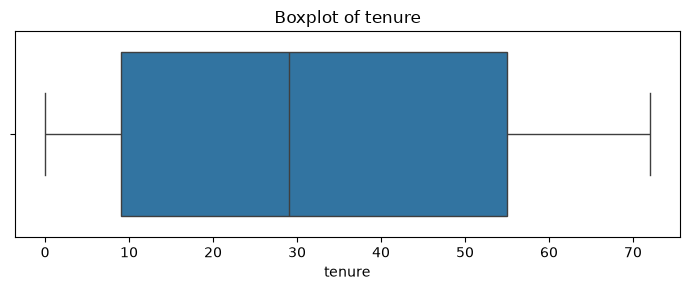

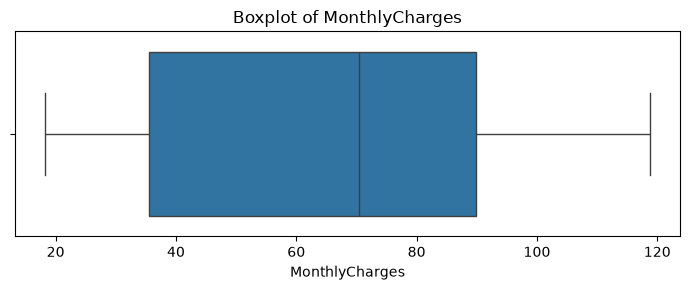

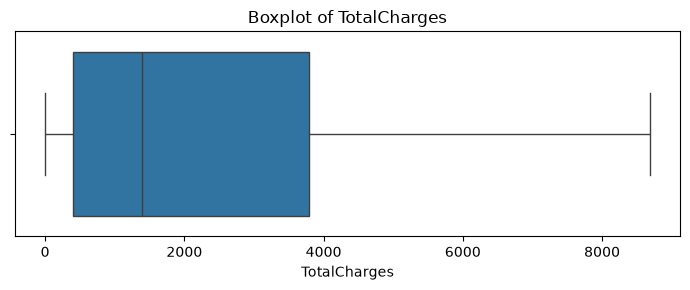

In [48]:
# Plotbox
for column in numerical_features:
    plt.figure(figsize=(7, 3))
    sns.boxplot(x=df[column])
    plt.title(f"Boxplot of {column}")
    plt.tight_layout()
    plt.show()

In [49]:
# Counting potential outliers using the IQR method
# The interquartile range method identifies values outside a statistical range.

for column in numerical_features:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(
        f"{column}: {len(outliers)} potential outliers"
    )

tenure: 0 potential outliers
MonthlyCharges: 0 potential outliers
TotalCharges: 0 potential outliers


# 3 Data visualisation

In [50]:
# Visualise the target distribution
print(df["Churn"].value_counts())

print(
    df["Churn"].value_counts(normalize=True).mul(100).round(2)
)

Churn
0    5174
1    1869
Name: count, dtype: int64
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64


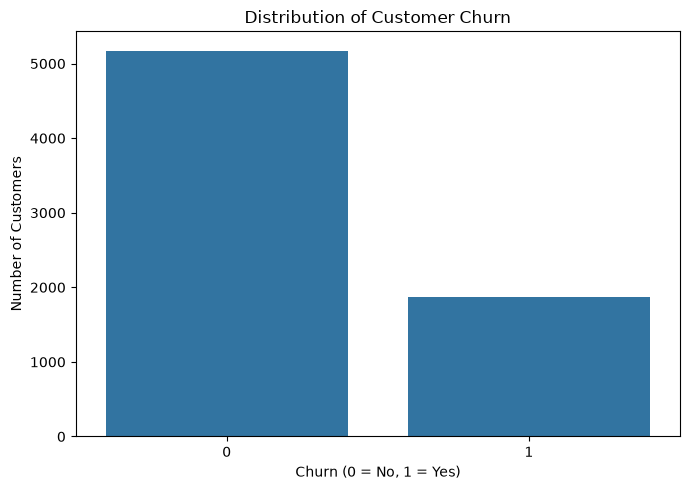

In [51]:
# Count visualization
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Churn"
)

plt.title("Distribution of Customer Churn")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

The dataset contains substantially more non-churning customers than churning customers, 
accuracy alone may give a misleading impression of performance.
We therefore need to evaluate precision, recall, F1-score, ROC-AUC, and the confusion matrix alongside accuracy


In [52]:
# Calculate the churn rate : The percentage of customers who churned
churn_rate = df["Churn"].mean() * 100

print(f"Overall churn rate: {churn_rate:.2f}%")

Overall churn rate: 26.54%


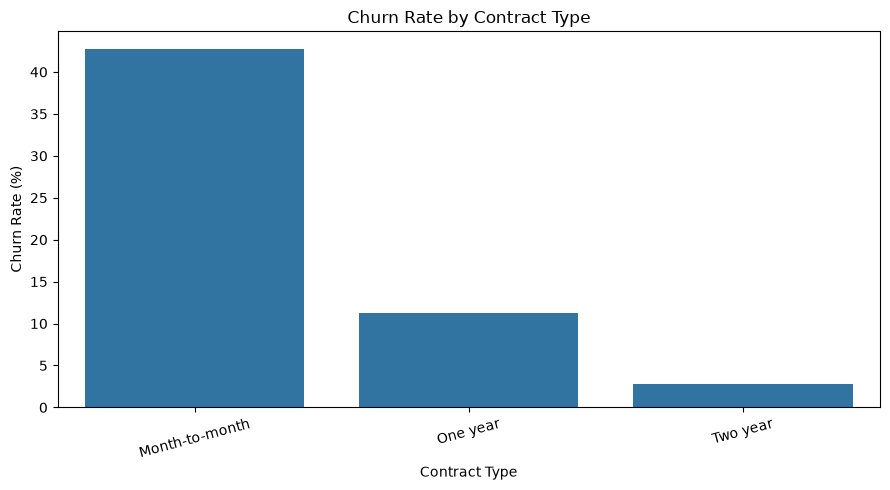

In [53]:
# The churn rate is 27%, approximately one in four customers in the dataset churned.
# Visualising churn rate by contract type. Contract type was the strongest categorical feature
contract_churn = (
    df.groupby("Contract", observed=True)["Churn"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=contract_churn.index,
    y=contract_churn.values
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


Contract type showed the strongest categorical association with churn in your analysis. This makes it a high-priority feature for prediction and further investigation.

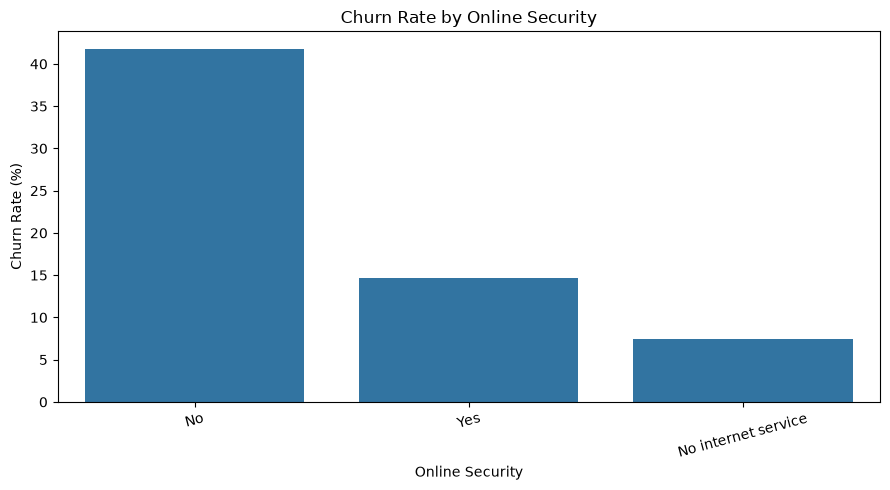

In [54]:
# Visualising churn rate by online security
security_churn = (
    df.groupby("OnlineSecurity", observed=True)["Churn"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=security_churn.index,
    y=security_churn.values
)

plt.title("Churn Rate by Online Security")
plt.xlabel("Online Security")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

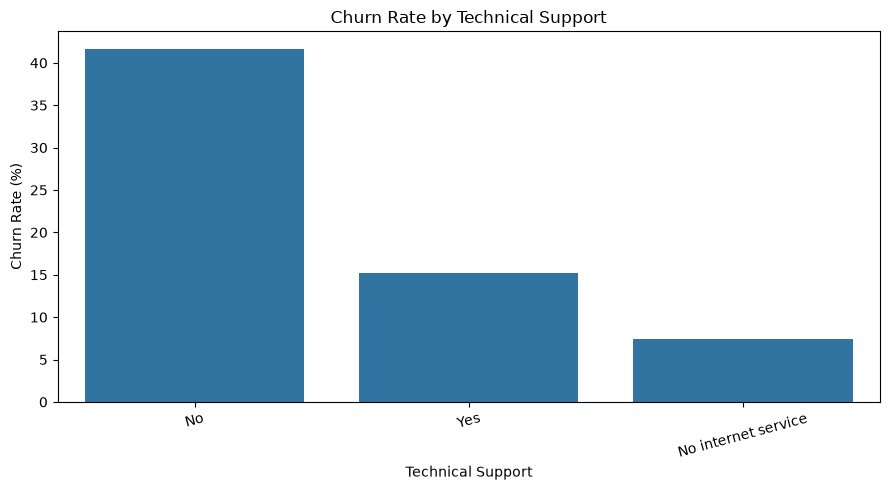

In [55]:
# Online security has a relatively strong association with churn

# Visualising churn rate by technical support
support_churn = (
    df.groupby("TechSupport", observed=True)["Churn"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=support_churn.index,
    y=support_churn.values
)

plt.title("Churn Rate by Technical Support")
plt.xlabel("Technical Support")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

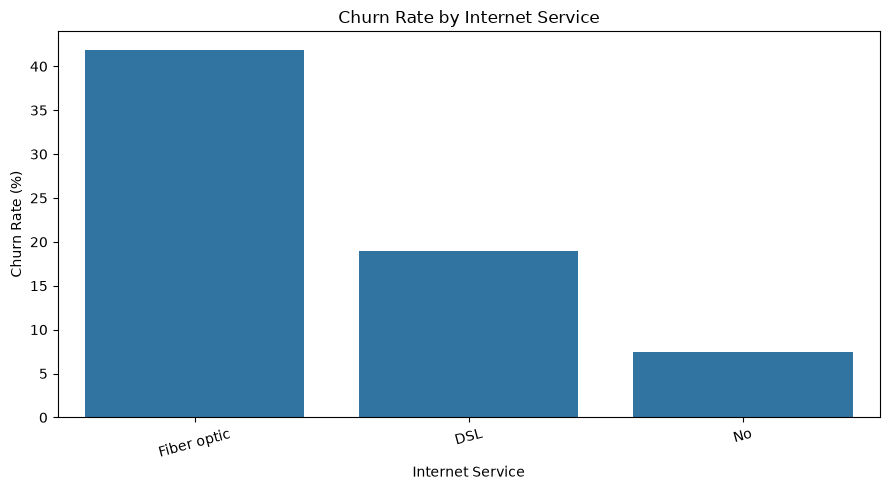

In [56]:
# Technical support is strongly associated with churn in my analysis

# Visualising churn rate by internet service
internet_churn = (
    df.groupby("InternetService", observed=True)["Churn"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=internet_churn.index,
    y=internet_churn.values
)

plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

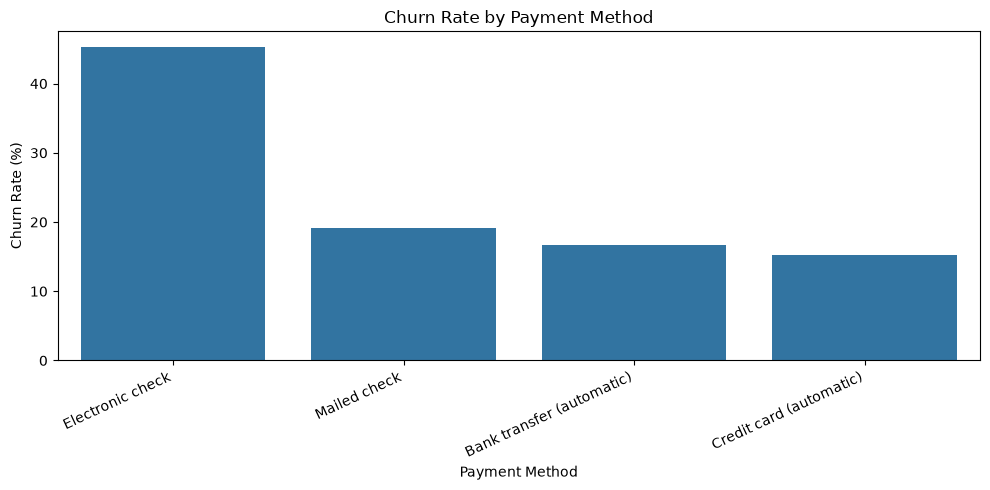

In [57]:
# Internet service type is associated with churn
# Visualising churn rate by payment method
payment_churn = (
    df.groupby("PaymentMethod", observed=True)["Churn"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=payment_churn.index,
    y=payment_churn.values
)

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

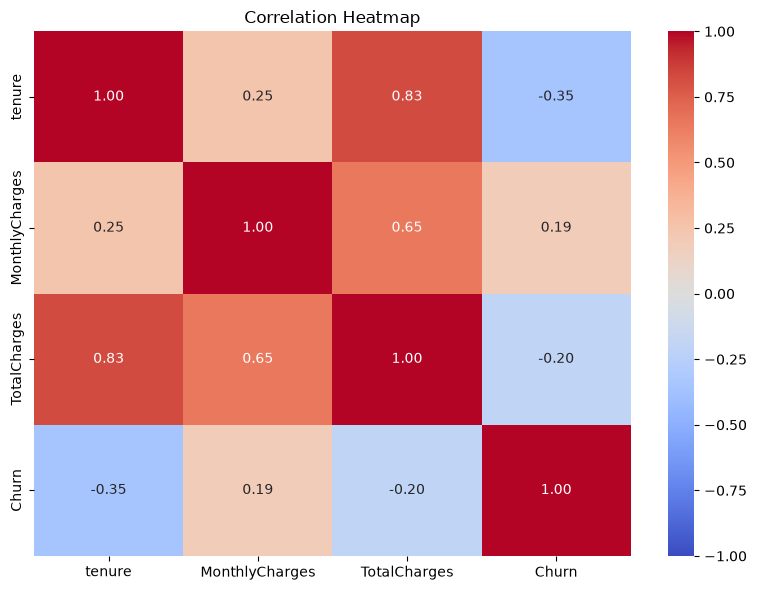

In [58]:
# Payment method is associated with churn
# Visualising numerical relationships using a correlation heatmap
numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "Churn"
]

correlation_matrix = df[numerical_features].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

# 4 Data preprocessing

In [60]:
# Selecting the five choosen features for the model based on the churn rate analysis

selected_features = [
    "Contract",
    "OnlineSecurity",
    "TechSupport",
    "InternetService",
    "PaymentMethod"
]

X = df[selected_features].copy()
y = df["Churn"].copy()

In [61]:
# Splitting the data before fitting preprocessing steps
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [63]:
# Handling missing values using an imputer
#Why use imputer? he imputer fills missing values using a rule learned from the training data.
# strategy="most_frequent" uses the most common value in each categorical column
# One-hot encoding: One-hot encoding converts each category into a binary indicator column

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

categorical_features = selected_features

categorical_pipeline = Pipeline(steps=[
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "encoder",
        OneHotEncoder(handle_unknown="ignore")
    )
])

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ]
)


In [64]:
# Fitting preprocessing on training data only
# Learn imputation values and categories from training data
X_train_encoded = preprocessor.fit_transform(X_train)

# Apply the learned transformations to testing data
X_test_encoded = preprocessor.transform(X_test)

print("Training data shape:", X_train_encoded.shape)
print("Testing data shape:", X_test_encoded.shape)


Training data shape: (5634, 16)
Testing data shape: (1409, 16)


### Scalling
For this initial model, the five selected features are categorical and have been one-hot encoded into binary indicators.
Scaling these indicators is generally unnecessary for Logistic Regression and tree-based models.
If i later add numerical features such as tenure, MonthlyCharges, and TotalCharges, scaling becomes more relevant


# 5 Problem type

My project is a supervised binary classification problem.

Why classification?

The objective is to predict a discrete outcome: whether a customer will churn.

The target has two classes:

Target value	        Meaning
0	            Customer does not churn
1	            Customer churns

Regression would be appropriate if we were predicting a continuous numerical value, such as the amount of money a customer might spend next month.

Here, we want to predict a category, so classification is the correct problem type.

# 6 Model comparison
MODELS:
Logistic Regression
Decision Tree
Random Forest
K-Nearest Neighbours

MATRIX:
Accuracy
Precision
Recall
F1-score
ROC-AUC
Confusion matrix

In [65]:
# Building the four models using the same split

import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

In [66]:
# Defining the input and target
selected_features = [
    "Contract",
    "OnlineSecurity",
    "TechSupport",
    "InternetService",
    "PaymentMethod"
]

X = df[selected_features].copy()
y = df["Churn"].copy()

In [67]:
# Splitting the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [68]:
# Defining preprocessing
categorical_features = selected_features

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            Pipeline(steps=[
                (
                    "imputer",
                    SimpleImputer(strategy="most_frequent")
                ),
                (
                    "encoder",
                    OneHotEncoder(handle_unknown="ignore")
                )
            ]),
            categorical_features
        )
    ]
)

In [69]:
# Defining the models

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        random_state=42
    )
}

In [70]:
# Training and evaluating the models

results = []
fitted_models = {}

for algorithm, classifier in models.items():

    # Combine preprocessing and the model into one pipeline
    model_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    # Train using training data only
    model_pipeline.fit(X_train, y_train)

    fitted_models[algorithm] = model_pipeline

    # Evaluate both training and testing data
    for dataset_name, X_data, y_data in [
        ("Train", X_train, y_train),
        ("Test", X_test, y_test)
    ]:

        y_pred = model_pipeline.predict(X_data)

        # Probability of belonging to the churn class
        y_proba = model_pipeline.predict_proba(X_data)[:, 1]

        results.append({
            "Algorithm": algorithm,
            "Dataset": dataset_name,

            "Accuracy": accuracy_score(
                y_data, y_pred
            ),

            "Precision": precision_score(
                y_data, y_pred, zero_division=0
            ),

            "Recall": recall_score(
                y_data, y_pred, zero_division=0
            ),

            "F1-score": f1_score(
                y_data, y_pred, zero_division=0
            ),

            "ROC-AUC": roc_auc_score(
                y_data, y_proba
            )
        })

performance_table = pd.DataFrame(results)

metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC"
]

performance_table[metric_columns] = (
    performance_table[metric_columns].round(3)
)

performance_table

,Algorithm,Dataset,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,Train,0.784,0.636,0.432,0.515,0.826
1,Logistic Regression,Test,0.764,0.584,0.390,0.468,0.813
2,Decision Tree,Train,0.785,0.652,0.403,0.498,0.828
3,Decision Tree,Test,0.769,0.605,0.369,0.458,0.810
4,Random Forest,Train,0.785,0.629,0.459,0.531,0.834
5,Random Forest,Test,0.774,0.601,0.439,0.507,0.808


In [71]:
# Creating one comparison table containing train and test scores

# Use Algorithm as the row index and Dataset as the column level
comparison = performance_table.pivot(
    index="Algorithm",
    columns="Dataset",
    values=metric_columns
)

# Flatten the column names
comparison.columns = [
    f"{metric}_{dataset}"
    for metric, dataset in comparison.columns
]

# Calculate train-test gaps
for metric in metric_columns:

    comparison[f"{metric}_Gap"] = (
        comparison[f"{metric}_Train"]
        - comparison[f"{metric}_Test"]
    )

comparison = comparison.round(3)

comparison

,Accuracy_Test,Accuracy_Train,Precision_Test,Precision_Train,Recall_Test,Recall_Train,F1-score_Test,F1-score_Train,ROC-AUC_Test,ROC-AUC_Train,Accuracy_Gap,Precision_Gap,Recall_Gap,F1-score_Gap,ROC-AUC_Gap
Algorithm,,,,,,,,,,,,,,,
Decision Tree,0.769,0.785,0.605,0.652,0.369,0.403,0.458,0.498,0.810,0.828,0.016,0.047,0.034,0.040,0.018
Logistic Regression,0.764,0.784,0.584,0.636,0.390,0.432,0.468,0.515,0.813,0.826,0.020,0.052,0.042,0.047,0.013
Random Forest,0.774,0.785,0.601,0.629,0.439,0.459,0.507,0.531,0.808,0.834,0.011,0.028,0.020,0.024,0.026


In [72]:
# Calculate the confusion matrix
# Random Forest is the best model based on the performance metrics and the train-test gap. 

best_model = fitted_models["Random Forest"]

y_test_pred = best_model.predict(X_test)

cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1]
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[926 109]
 [210 164]]


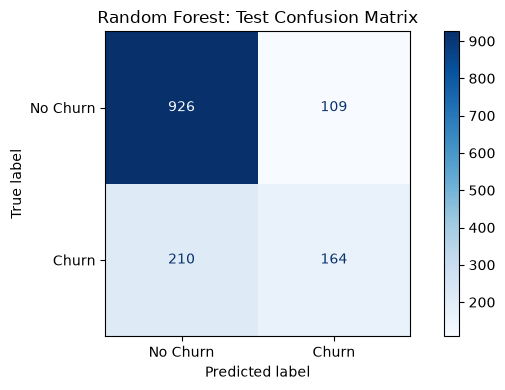

In [73]:
# Confusion matric chart

from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(
    best_model,
    X_test,
    y_test,
    labels=[0, 1],
    display_labels=["No Churn", "Churn"],
    cmap="Blues"
)

plt.title("Random Forest: Test Confusion Matrix")
plt.tight_layout()
plt.show()

# 7 The Best algorithm and why

Based on my results, I would select Random Forest as the leading candidate for further evaluation, while retaining Logistic Regression as an important benchmark.


The smaller gaps for Random Forest on accuracy, precision, recall, and F1-score are encouraging.

Comparing interpretability and speed


Logistic Regression:
Interpretability- Generally easier to explain through its coefficients
Training speed - Usually fast on a dataset of this size
Predictive relationships - Learns a linear relationship in the encoded features unless extended

Accuracy Test - 76.4%
Recall Test - 39.0%
F1-score Test - 0.468
ROC-AUC Test - 0.813




Random Forest:
Interpretability - More complex because predictions combine many trees
Training speed - Usually reasonable, but more computationally intensive
Predictive relationships - Can learn more complex interactions between features
Accuracy Test - 77.4%
Recall Test - 43.9%
F1-score Test - 0.507
ROC-AUC Test - 0.808





In [74]:
# Tuning the Random Forest using cross-validation
# Because identifying churners is important, we will use recall as the tuning metric for this.
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

# Define the preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            Pipeline(steps=[
                (
                    "imputer",
                    SimpleImputer(strategy="most_frequent")
                ),
                (
                    "encoder",
                    OneHotEncoder(handle_unknown="ignore")
                )
            ]),
            selected_features
        )
    ]
)

# Create a pipeline
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    (
        "classifier",
        RandomForestClassifier(
            random_state=42,
            class_weight="balanced"
        )
    )
])

# Define the hyperparameters to test
param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [5, 10, None],
    "classifier__min_samples_split": [2, 10],
    "classifier__min_samples_leaf": [1, 5]
}

# Use stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring="recall",
    cv=cv,
    n_jobs=-1,
    refit=True
)

# Fit using training data only
grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest mean cross-validation recall:")
print(round(grid_search.best_score_, 3))

Best parameters:
{'classifier__max_depth': 5, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 100}

Best mean cross-validation recall:
0.791
